In [19]:
pip install graphviz


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn import datasets, model_selection, metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cancer_dataset = datasets.load_breast_cancer()
df = pd.DataFrame(data= cancer_dataset.data, columns=cancer_dataset.feature_names)
df['TARGET'] = cancer_dataset.target
pd.set_option('display.max_columns', None)
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,TARGET
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [21]:
df.tail(10)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,TARGET
559,11.51,23.93,74.52,403.5,0.09261,0.10210,0.11120,0.04105,0.1388,0.06570,0.2388,2.904,1.936,16.97,0.008200,0.029820,0.05738,0.01267,0.01488,0.004738,12.480,37.16,82.28,474.2,0.12980,0.25170,0.3630,0.09653,0.2112,0.08732,1
560,14.05,27.15,91.38,600.4,0.09929,0.11260,0.04462,0.04304,0.1537,0.06171,0.3645,1.492,2.888,29.84,0.007256,0.026780,0.02071,0.01626,0.02080,0.005304,15.300,33.17,100.20,706.7,0.12410,0.22640,0.1326,0.10480,0.2250,0.08321,1
561,11.20,29.37,70.67,386.0,0.07449,0.03558,0.00000,0.00000,0.1060,0.05502,0.3141,3.896,2.041,22.81,0.007594,0.008878,0.00000,0.00000,0.01989,0.001773,11.920,38.30,75.19,439.6,0.09267,0.05494,0.0000,0.00000,0.1566,0.05905,1
562,15.22,30.62,103.40,716.9,0.10480,0.20870,0.25500,0.09429,0.2128,0.07152,0.2602,1.205,2.362,22.65,0.004625,0.048440,0.07359,0.01608,0.02137,0.006142,17.520,42.79,128.70,915.0,0.14170,0.79170,1.1700,0.23560,0.4089,0.14090,0
563,20.92,25.09,143.00,1347.0,0.10990,0.22360,0.31740,0.14740,0.2149,0.06879,0.9622,1.026,8.758,118.80,0.006399,0.043100,0.07845,0.02624,0.02057,0.006213,24.290,29.41,179.10,1819.0,0.14070,0.41860,0.6599,0.25420,0.2929,0.09873,0
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.256,7.673,158.70,0.010300,0.028910,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.22160,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.463,5.203,99.04,0.005769,0.024230,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.16280,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.075,3.425,48.55,0.005903,0.037310,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.14180,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.595,5.772,86.22,0.006522,0.061580,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.26500,0.4087,0.12400,0
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,0.3857,1.428,2.548,19.15,0.007189,0.004660,0.00000,0.00000,0.02676,0.002783,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.00000,0.2871,0.07039,1


In [22]:
features = df[['worst area','worst smoothness', 'area error','mean symmetry','mean texture','worst radius','mean smoothness','fractal dimension error']]
label = df['TARGET']

In [23]:
X_train, X_test, y_train, y_test = train_test_split(features, label, test_size= 0.2, random_state= 42)

print('the number of training records',X_train.count())
print('the number of testind records',X_test.count())

the number of training records worst area                 455
worst smoothness           455
area error                 455
mean symmetry              455
mean texture               455
worst radius               455
mean smoothness            455
fractal dimension error    455
dtype: int64
the number of testind records worst area                 114
worst smoothness           114
area error                 114
mean symmetry              114
mean texture               114
worst radius               114
mean smoothness            114
fractal dimension error    114
dtype: int64


In [24]:
model = KNeighborsClassifier(n_neighbors= 99)

model.fit(X_train, y_train)
y_train_pred_knn = model.predict(X_train)
y_test_pred_knn = model.predict(X_test)
#y_pred = model.predict(X_test)

In [25]:
# Calculate and display accuracy, precision, specificity, and F1 score
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

accuracy_train = accuracy_score(y_train, y_train_pred_knn)
precision_train = precision_score(y_train, y_train_pred_knn)
recall_train= recall_score(y_train, y_train_pred_knn)
f1_train = f1_score(y_train, y_train_pred_knn)

print(f'Accuracy: {accuracy_train:.2f}')
print(f'Precision: {precision_train:.2f}')
print(f'Recall: {recall_train:.2f}')
print(f'F1 Score: {f1_train:.2f}')

Accuracy: 0.91
Precision: 0.90
Recall: 0.97
F1 Score: 0.93


In [26]:
# Calculate and display accuracy, precision, specificity, and F1 score
accuracy_test = accuracy_score(y_test, y_test_pred_knn)
precision_test = precision_score(y_test, y_test_pred_knn)
recall_test = recall_score(y_test, y_test_pred_knn)
f1_test = f1_score(y_test, y_test_pred_knn)

print(f'Accuracy: {accuracy_test:.2f}')
print(f'Precision: {precision_test:.2f}')
print(f'Recall: {recall_test:.2f}')
print(f'F1 Score: {f1_test:.2f}')

Accuracy: 0.95
Precision: 0.92
Recall: 1.00
F1 Score: 0.96


In [27]:
# print the confusion matrix
print("confusion_matrix for test\n", confusion_matrix(y_test, y_test_pred_knn))

print("confusion_matrix for train\n", confusion_matrix(y_train, y_train_pred_knn))


confusion_matrix for test
 [[37  6]
 [ 0 71]]
confusion_matrix for train
 [[139  30]
 [  9 277]]


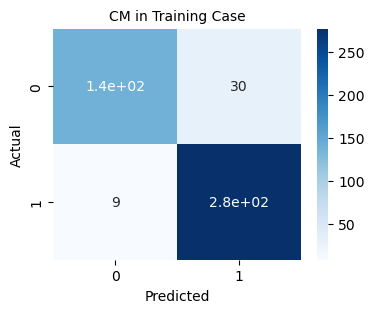

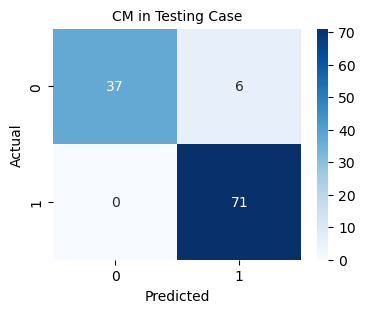

In [28]:
# visulaize the confusion matrix
# visulaize the confusion matrix
cm = confusion_matrix(y_train, y_train_pred_knn)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot= True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CM in Training Case', fontsize= 10)
plt.savefig('cm_knn_train_fs.pdf')

cm = confusion_matrix(y_test, y_test_pred_knn)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot= True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CM in Testing Case', fontsize= 10)
plt.savefig('cm_knn_test_fs.pdf')
plt.show()

In [29]:
##### Decision Tree #####

In [30]:
# apply feature scaling

sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

In [31]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt = DecisionTreeClassifier(max_depth= 3, random_state= 42)
dt.fit(X_train_scaled, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [32]:
y_train_pred_dt = dt.predict(X_train_scaled)
y_test_pred_dt = dt.predict(X_test_scaled)

In [33]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

##### Training Data
train_accuracy = accuracy_score(y_train, y_train_pred_dt)
train_precision = precision_score(y_train, y_train_pred_dt)
train_recall = recall_score(y_train, y_train_pred_dt)
train_f1 = f1_score(y_train, y_train_pred_dt)

##### Testing Data
test_accuracy = accuracy_score(y_test, y_test_pred_dt)
test_precision = precision_score(y_test, y_test_pred_dt)
test_recall = recall_score(y_test, y_test_pred_dt)
test_f1 = f1_score(y_test, y_test_pred_dt)

In [34]:
results_df = pd.DataFrame ({
    'Metric':['Accuracy', 'Precision', 'Recal', 'F1_Score'],
    'Training' : [train_accuracy, test_precision, train_recall, train_f1],
    'Testing': [test_accuracy, test_precision, test_recall, test_f1]
})

results_df.T

,0,1,2,3
Metric,Accuracy,Precision,Recal,F1_Score
Training,0.953846,0.934211,0.98951,0.964225
Testing,0.95614,0.934211,1.0,0.965986


In [35]:
# print the confusion matrix
print("confusion_matrix for test\n", confusion_matrix(y_test, y_test_pred_dt))

print("confusion_matrix for train\n", confusion_matrix(y_train, y_train_pred_dt))

cm_train = confusion_matrix(y_train, y_train_pred_dt)
cm_test = confusion_matrix(y_test, y_test_pred_dt)



confusion_matrix for test
 [[38  5]
 [ 0 71]]
confusion_matrix for train
 [[151  18]
 [  3 283]]


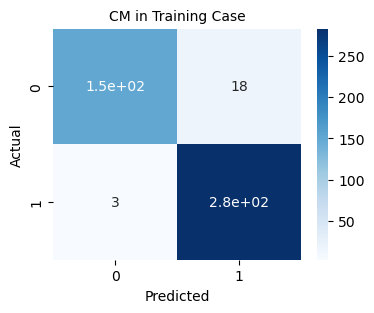

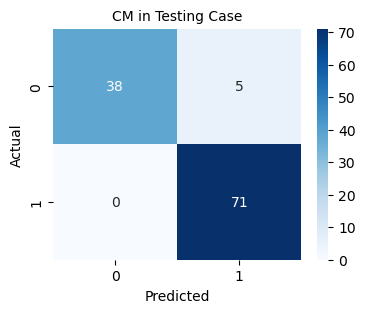

In [36]:
# visulaize the results
cm = confusion_matrix(y_train, y_train_pred_dt)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot= True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CM in Training Case', fontsize= 10)
plt.savefig('cm_dt_train_fs.pdf')

cm = confusion_matrix(y_test, y_test_pred_dt)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot= True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CM in Testing Case', fontsize= 10)
plt.savefig('cm_dt_test_fs.pdf')

plt.show()

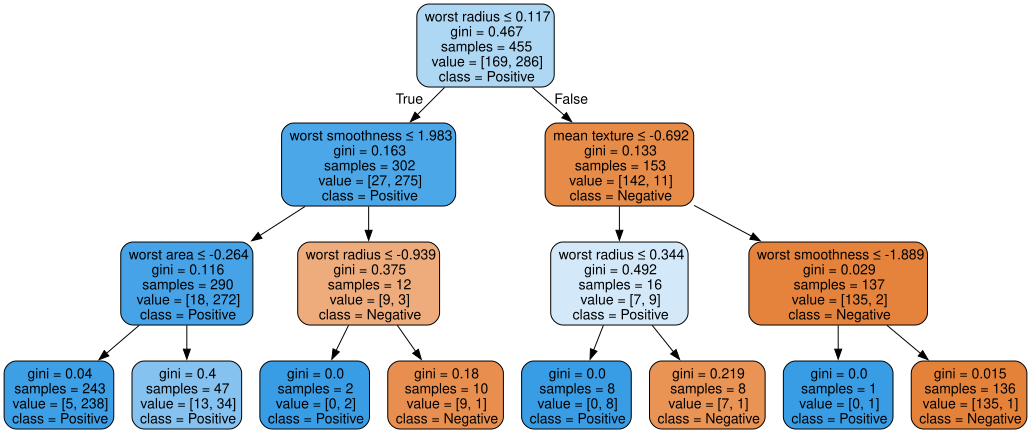

In [38]:
from sklearn.tree import export_graphviz
import graphviz

selected_feature_names =  ['worst area', 'worst smoothness', 'area error', 'mean symmetry', 'mean texture', 'worst radius', 'mean smoothness', 'fractal dimension error']

# Export the tree as a Graphviz dot file
dot_data = export_graphviz(dt, out_file=None, feature_names= selected_feature_names,
                           class_names=['Negative', 'Positive'], filled=True, rounded=True,
                           special_characters=True, rotate=False)

# Create a graph from the dot file
graph = graphviz.Source(dot_data)

# # Render the graph as a PNG image
# graph.format = 'png'
# graph.render('decision tree', view=False)

graph.format = 'pdf'
graph.render('decision_tree', view=True)  # view=True opens the PDF automatically

# Display the graph
graph

In [39]:
#### SVC ######

In [40]:
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(features, label, test_size= 0.2, random_state= 42)

print('the number of training records',X_train.count())
print('the number of testind records',X_test.count())

# Define kernels to test
kernels = ['linear']

for kernel in kernels:
    print(f"\nSVM with {kernel} kernel")

    # Create SVM model with the specified kernel
    model = SVC(kernel=kernel, gamma='scale', C=1.0)

    # Train the model
    model.fit(X_train, y_train)

    # Predict
    y_train_pred_SVC= model.predict(X_train)
    y_test_pred_SVC = model.predict(X_test)

    # # Evaluate
    # print("Accuracy:", accuracy_score(y_test, y_pred))
    # print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    # print("Classification Report:\n", classification_report(y_test, y_pred))

    ##### Training Data
    train_accuracy = accuracy_score(y_train, y_train_pred_SVC)
    train_precision = precision_score(y_train, y_train_pred_SVC)
    train_recall = recall_score(y_train, y_train_pred_SVC)
    train_f1 = f1_score(y_train, y_train_pred_SVC)

    ##### Testing Data
    test_accuracy = accuracy_score(y_test, y_test_pred_SVC)
    test_precision = precision_score(y_test, y_test_pred_SVC)
    test_recall = recall_score(y_test, y_test_pred_SVC)
    test_f1 = f1_score(y_test, y_test_pred_SVC)

    # Evaluate
    print("Accuracy:", train_accuracy)
    print("Accuracy:", test_accuracy)
    print("Confusion Matrix:\n", confusion_matrix(y_train, y_train_pred_SVC))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred_SVC))
    print("Classification Report:\n", classification_report(y_train, y_train_pred_SVC))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred_SVC))
    print("Classification Report:\n", classification_report(y_test, y_test_pred_SVC))


    # results_df = pd.DataFrame ({
    #     'Metric':['Accuracy', 'Precision', 'Recall', 'F1_Score'],
    #     'Training' : [train_accuracy, test_precision, train_recall, train_f1],
    #     'Testing': [test_accuracy, test_precision, test_recall, test_f1]
    # })

    # results_df.T

the number of training records worst area                 455
worst smoothness           455
area error                 455
mean symmetry              455
mean texture               455
worst radius               455
mean smoothness            455
fractal dimension error    455
dtype: int64
the number of testind records worst area                 114
worst smoothness           114
area error                 114
mean symmetry              114
mean texture               114
worst radius               114
mean smoothness            114
fractal dimension error    114
dtype: int64

SVM with linear kernel
Accuracy: 0.9362637362637363
Accuracy: 0.9473684210526315
Confusion Matrix:
 [[149  20]
 [  9 277]]
Confusion Matrix:
 [[39  4]
 [ 2 69]]
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.88      0.91       169
           1       0.93      0.97      0.95       286

    accuracy                           0.94       455
   macro avg 

In [42]:
features = df.drop('TARGET', axis=1)  # Select all columns except the label
label = df['TARGET']                  # Target/label column

Accuracy: 0.91
Precision: 0.90
Recall: 0.97
F1 Score: 0.93
Accuracy: 0.95
Precision: 0.92
Recall: 1.00
F1 Score: 0.96
confusion_matrix for test
 [[37  6]
 [ 0 71]]
confusion_matrix for train
 [[139  30]
 [  9 277]]


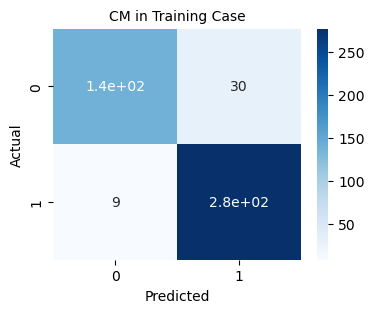

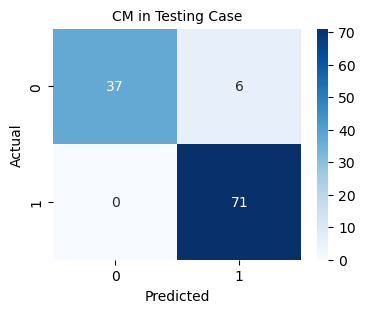

In [43]:
model = KNeighborsClassifier(n_neighbors= 99)

model.fit(X_train, y_train)
y_train_pred_knn1 = model.predict(X_train)
y_test_pred_knn1 = model.predict(X_test)
#y_pred = model.predict(X_test)

# Calculate and display accuracy, precision, specificity, and F1 score
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

accuracy_train = accuracy_score(y_train, y_train_pred_knn1)
precision_train = precision_score(y_train, y_train_pred_knn1)
recall_train= recall_score(y_train, y_train_pred_knn1)
f1_train = f1_score(y_train, y_train_pred_knn1)

print(f'Accuracy: {accuracy_train:.2f}')
print(f'Precision: {precision_train:.2f}')
print(f'Recall: {recall_train:.2f}')
print(f'F1 Score: {f1_train:.2f}')
# Calculate and display accuracy, precision, specificity, and F1 score
accuracy_test = accuracy_score(y_test, y_test_pred_knn1)
precision_test = precision_score(y_test, y_test_pred_knn1)
recall_test = recall_score(y_test, y_test_pred_knn1)
f1_test = f1_score(y_test, y_test_pred_knn1)

print(f'Accuracy: {accuracy_test:.2f}')
print(f'Precision: {precision_test:.2f}')
print(f'Recall: {recall_test:.2f}')
print(f'F1 Score: {f1_test:.2f}')

# print the confusion matrix
print("confusion_matrix for test\n", confusion_matrix(y_test, y_test_pred_knn1))

print("confusion_matrix for train\n", confusion_matrix(y_train, y_train_pred_knn1))

# visulaize the confusion matrix
# visulaize the confusion matrix
cm = confusion_matrix(y_train, y_train_pred_knn1)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot= True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CM in Training Case', fontsize= 10)
plt.savefig('cm_knn_train_fs.pdf')

cm = confusion_matrix(y_test, y_test_pred_knn1)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot= True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CM in Testing Case', fontsize= 10)
plt.savefig('cm_knn_test_fs.pdf')
plt.show()

confusion_matrix for test
 [[38  5]
 [ 0 71]]
confusion_matrix for train
 [[151  18]
 [  3 283]]


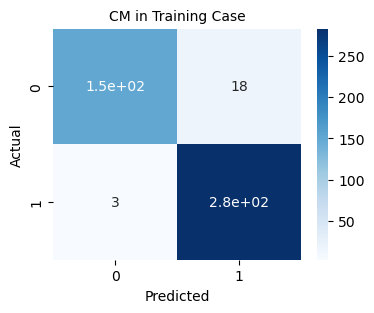

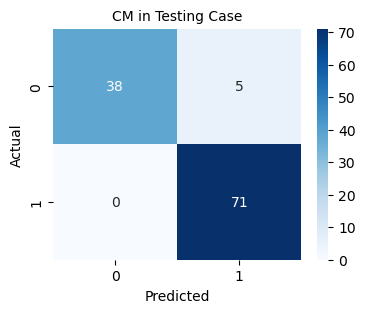

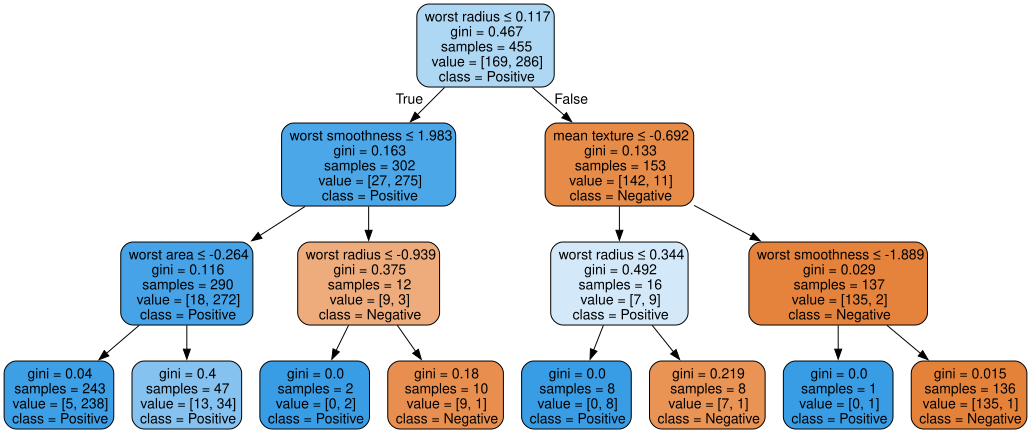

In [44]:
##### DT  #####

# apply feature scaling

sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

from sklearn.tree import DecisionTreeClassifier, plot_tree

dt = DecisionTreeClassifier(max_depth= 3, random_state= 42)
dt.fit(X_train_scaled, y_train)

y_train_pred_dt1 = dt.predict(X_train_scaled)
y_test_pred_dt1 = dt.predict(X_test_scaled)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

##### Training Data
train_accuracy = accuracy_score(y_train, y_train_pred_dt1)
train_precision = precision_score(y_train, y_train_pred_dt1)
train_recall = recall_score(y_train, y_train_pred_dt1)
train_f1 = f1_score(y_train, y_train_pred_dt1)

##### Testing Data
test_accuracy = accuracy_score(y_test, y_test_pred_dt1)
test_precision = precision_score(y_test, y_test_pred_dt1)
test_recall = recall_score(y_test, y_test_pred_dt1)
test_f1 = f1_score(y_test, y_test_pred_dt1)

results_df = pd.DataFrame ({
    'Metric':['Accuracy', 'Precision', 'Recal', 'F1_Score'],
    'Training' : [train_accuracy, test_precision, train_recall, train_f1],
    'Testing': [test_accuracy, test_precision, test_recall, test_f1]
})

results_df.T
# print the confusion matrix
print("confusion_matrix for test\n", confusion_matrix(y_test, y_test_pred_dt1))

print("confusion_matrix for train\n", confusion_matrix(y_train, y_train_pred_dt1))

cm_train = confusion_matrix(y_train, y_train_pred_dt1)
cm_test = confusion_matrix(y_test, y_test_pred_dt1)

# visulaize the results
cm = confusion_matrix(y_train, y_train_pred_dt1)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot= True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CM in Training Case', fontsize= 10)
plt.savefig('cm_dt_train_fs.pdf')

cm = confusion_matrix(y_test, y_test_pred_dt1)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot= True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CM in Testing Case', fontsize= 10)
plt.savefig('cm_dt_test_fs.pdf')

plt.show()

from sklearn.tree import export_graphviz
import graphviz

selected_feature_names =  ['worst area', 'worst smoothness', 'area error', 'mean symmetry', 'mean texture', 'worst radius', 'mean smoothness', 'fractal dimension error']

# Export the tree as a Graphviz dot file
dot_data = export_graphviz(dt, out_file=None, feature_names= selected_feature_names,
                           class_names=['Negative', 'Positive'], filled=True, rounded=True,
                           special_characters=True, rotate=False)

# Create a graph from the dot file
graph = graphviz.Source(dot_data)

# # Render the graph as a PNG image
# graph.format = 'png'
# graph.render('decision tree', view=False)

graph.format = 'pdf'
graph.render('decision_tree', view=True)  # view=True opens the PDF automatically

# Display the graph
graph

the number of training records mean radius                455
mean texture               455
mean perimeter             455
mean area                  455
mean smoothness            455
mean compactness           455
mean concavity             455
mean concave points        455
mean symmetry              455
mean fractal dimension     455
radius error               455
texture error              455
perimeter error            455
area error                 455
smoothness error           455
compactness error          455
concavity error            455
concave points error       455
symmetry error             455
fractal dimension error    455
worst radius               455
worst texture              455
worst perimeter            455
worst area                 455
worst smoothness           455
worst compactness          455
worst concavity            455
worst concave points       455
worst symmetry             455
worst fractal dimension    455
dtype: int64
the number of testind reco

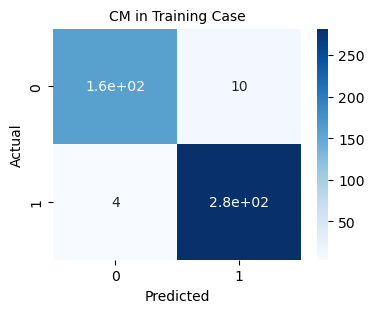

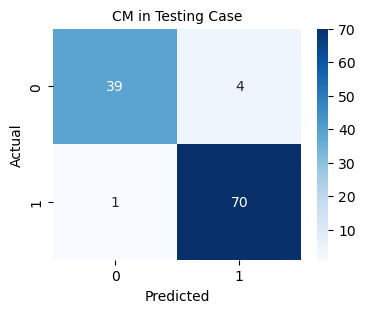

In [45]:
#### SVC  ####
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(features, label, test_size= 0.2, random_state= 42)

print('the number of training records',X_train.count())
print('the number of testind records',X_test.count())

# Define kernels to test
kernels = ['linear']

for kernel in kernels:
    print(f"\nSVM with {kernel} kernel")

    # Create SVM model with the specified kernel
    model = SVC(kernel=kernel, gamma='scale', C=1.0)

    # Train the model
    model.fit(X_train, y_train)

    # Predict
    y_train_pred_SVC1= model.predict(X_train)
    y_test_pred_SVC1= model.predict(X_test)

    # # Evaluate
    # print("Accuracy:", accuracy_score(y_test, y_pred))
    # print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    # print("Classification Report:\n", classification_report(y_test, y_pred))

    ##### Training Data
    train_accuracy = accuracy_score(y_train, y_train_pred_SVC1)
    train_precision = precision_score(y_train, y_train_pred_SVC1)
    train_recall = recall_score(y_train, y_train_pred_SVC1)
    train_f1 = f1_score(y_train, y_train_pred_SVC1)

    ##### Testing Data
    test_accuracy = accuracy_score(y_test, y_test_pred_SVC1)
    test_precision = precision_score(y_test, y_test_pred_SVC1)
    test_recall = recall_score(y_test, y_test_pred_SVC1)
    test_f1 = f1_score(y_test, y_test_pred_SVC1)

    # Evaluate
    print("Accuracy:", train_accuracy)
    print("Accuracy:", test_accuracy)
    print("Confusion Matrix:\n", confusion_matrix(y_train, y_train_pred_SVC1))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred_SVC1))
    print("Classification Report:\n", classification_report(y_train, y_train_pred_SVC1))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred_SVC1))
    print("Classification Report:\n", classification_report(y_test, y_test_pred_SVC1))


    # results_df = pd.DataFrame ({
    #     'Metric':['Accuracy', 'Precision', 'Recall', 'F1_Score'],
    #     'Training' : [train_accuracy, test_precision, train_recall, train_f1],
    #     'Testing': [test_accuracy, test_precision, test_recall, test_f1]
    # })

    # results_df.T

    # visulaize the results
cm = confusion_matrix(y_train, y_train_pred_SVC1)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot= True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CM in Training Case', fontsize= 10)
plt.savefig('cm_svm_train_fs.pdf')

cm = confusion_matrix(y_test, y_test_pred_SVC1)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot= True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CM in Testing Case', fontsize= 10)
plt.savefig('cm_svm_test_fs.pdf')

plt.show()

# # visulaize the results

# cm_train = confusion_matrix(y_train, y_train_pred)
# cm_test = confusion_matrix(y_test, y_test_pred_SVC)

# plt.figure(figsize= (3, 5))

# plt.subplot(2, 1, 1)
# sns.heatmap(cm_train, annot = True, cmap='Blues', fmt='0.1f')
# plt.xlabel('Predicted')
# plt.ylabel('Actual')
# plt.title('CM in Training Case', fontsize= 10)
# plt.savefig('cm_svm_train_fs.pdf')

# plt.subplots_adjust(hspace=0.5)

# plt.subplot(2, 1, 2)
# sns.heatmap(cm_test, annot = True, cmap='Blues', fmt='0.1f')
# plt.xlabel('Predicted')
# plt.ylabel('Actual')
# plt.title('CM in Testing Case', fontsize= 10)
# plt.savefig('cm_svm_test_fs.pdf')

# plt.show()

In [115]:
from statsmodels.stats.contingency_tables import mcnemar

# 1. Calculate who got what right
knn_correct = (y_test_pred_knn == y_test)
svm_correct = (y_test_pred_knn1 == y_test)

# 2. Build the contingency table
# a: Both correct
a = sum(knn_correct & svm_correct)
# b: KNN correct, SVM wrong
b = sum(knn_correct & ~svm_correct)
# c: KNN wrong, SVM right
c = sum(~knn_correct & svm_correct)
# d: Both wrong
d = sum(~knn_correct & ~svm_correct)

table = [[a, b], [c, d]]

print(f"Table for FRQR KNN vs FULL FEATURE KNN: \n{a} (Both Right), {b} (FRQR KNN only)\n{c} (FULL FEATURE KNN only), {d} (Both Wrong)")
# 3. Run the test
# exact=False uses Chi-Squared distribution (better for larger test sets > 20)
result = mcnemar(table, exact=False, correction=True) 

print(f"p-value: {result.pvalue}")
if result.pvalue < 0.05:
    print("Statistically significant difference between FRQR Feature selection and No feature selection")
else:
    print("No statistically significant difference")

Table for FRQR KNN vs FULL FEATURE KNN: 
108 (Both Right), 0 (FRQR KNN only)
0 (FULL FEATURE KNN only), 6 (Both Wrong)
p-value: 0.0
Statistically significant difference between FRQR Feature selection and No feature selection


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/stats/contingency_tables.py:1348: RuntimeWarning: divide by zero encountered in scalar divide
  statistic = (np.abs(n1 - n2) - corr)**2 / (1. * (n1 + n2))


In [116]:
from statsmodels.stats.contingency_tables import mcnemar

# 1. Calculate who got what right
knn_correct = (y_test_pred_dt == y_test)
svm_correct = (y_test_pred_dt1 == y_test)

# 2. Build the contingency table
# a: Both correct
a = sum(knn_correct & svm_correct)
# b: KNN correct, SVM wrong
b = sum(knn_correct & ~svm_correct)
# c: KNN wrong, SVM right
c = sum(~knn_correct & svm_correct)
# d: Both wrong
d = sum(~knn_correct & ~svm_correct)

table = [[a, b], [c, d]]

print(f"Table for FRQR DT vs FULL FEATURE DT: \n{a} (Both Right), {b} (FRQR DT only)\n{c} (FULL FEATURE DT only), {d} (Both Wrong)")
# 3. Run the test
# exact=False uses Chi-Squared distribution (better for larger test sets > 20)
result = mcnemar(table, exact=False, correction=True) 

print(f"p-value: {result.pvalue}")
if result.pvalue < 0.05:
    print("Statistically significant difference between FRQR Feature selection and No feature selection")
else:
    print("No statistically significant difference")

Table for FRQR DT vs FULL FEATURE DT: 
109 (Both Right), 0 (FRQR DT only)
0 (FULL FEATURE DT only), 5 (Both Wrong)
p-value: 0.0
Statistically significant difference between FRQR Feature selection and No feature selection


In [117]:
from statsmodels.stats.contingency_tables import mcnemar

# 1. Calculate who got what right
knn_correct = (y_test_pred_SVC == y_test)
svm_correct = (y_test_pred_SVC1 == y_test)

# 2. Build the contingency table
# a: Both correct
a = sum(knn_correct & svm_correct)
# b: KNN correct, SVM wrong
b = sum(knn_correct & ~svm_correct)
# c: KNN wrong, SVM right
c = sum(~knn_correct & svm_correct)
# d: Both wrong
d = sum(~knn_correct & ~svm_correct)

table = [[a, b], [c, d]]

print(f"Table for FRQR SVM vs FULL FEATURE SVM: \n{a} (Both Right), {b} (FRQR SVM only)\n{c} (FULL FEATURE SVM only), {d} (Both Wrong)")
# 3. Run the test
# exact=False uses Chi-Squared distribution (better for larger test sets > 20)
result = mcnemar(table, exact=False, correction=True) 

print(f"p-value: {result.pvalue}")
if result.pvalue < 0.05:
    print("Statistically significant difference between FRQR Feature selection and No feature selection")
else:
    print("No statistically significant difference")

Table for FRQR SVM vs FULL FEATURE SVM: 
107 (Both Right), 1 (FRQR SVM only)
2 (FULL FEATURE SVM only), 4 (Both Wrong)
p-value: 1.0
No statistically significant difference


In [77]:
##### Statistical evaluation. #####

In [84]:
from statsmodels.stats.contingency_tables import mcnemar

# 1. Calculate who got what right
knn_correct = (y_test_pred_knn == y_test)
svm_correct = (y_test_pred_SVC == y_test)

# 2. Build the contingency table
# a: Both correct
a = sum(knn_correct & svm_correct)
# b: KNN correct, SVM wrong
b = sum(knn_correct & ~svm_correct)
# c: KNN wrong, SVM right
c = sum(~knn_correct & svm_correct)
# d: Both wrong
d = sum(~knn_correct & ~svm_correct)

table = [[a, b], [c, d]]

print(f"Table for KNN vs SVM: \n{a} (Both Right), {b} (KNN only)\n{c} (DT only), {d} (Both Wrong)")
# 3. Run the test
# exact=False uses Chi-Squared distribution (better for larger test sets > 20)
result = mcnemar(table, exact=False, correction=True) 

print(f"p-value: {result.pvalue}")
if result.pvalue < 0.05:
    print("Statistically significant difference between KNN and SVM")
else:
    print("No statistically significant difference")

Table for KNN vs SVM: 
106 (Both Right), 2 (KNN only)
2 (DT only), 4 (Both Wrong)
p-value: 0.6170750774519739
No statistically significant difference


In [85]:
from statsmodels.stats.contingency_tables import mcnemar

# 1. Calculate who got what right
knn_correct = (y_test_pred_knn == y_test)
dt_correct = (y_test_pred_dt == y_test)

# 2. Build the contingency table
# a: Both correct
a = sum(knn_correct & dt_correct)
# b: KNN correct, SVM wrong
b = sum(knn_correct & ~dt_correct)
# c: KNN wrong, SVM right
c = sum(~knn_correct & dt_correct)
# d: Both wrong
d = sum(~knn_correct & ~dt_correct)

table = [[a, b], [c, d]]
print(f"Table for KNN vs DT: \n{a} (Both Right), {b} (KNN only)\n{c} (DT only), {d} (Both Wrong)")
# 3. Run the test
# exact=False uses Chi-Squared distribution (better for larger test sets > 20)
result = mcnemar(table, exact=False, correction=True) 

print(f"p-value: {result.pvalue}")
if result.pvalue < 0.05:
    print("Statistically significant difference between KNN and SVM")
else:
    print("No statistically significant difference")

Table for KNN vs DT: 
108 (Both Right), 0 (KNN only)
1 (DT only), 5 (Both Wrong)
p-value: 1.0
No statistically significant difference


In [86]:
from statsmodels.stats.contingency_tables import mcnemar

# 1. Calculate who got what right
knn_correct = (y_test_pred_dt == y_test)
svm_correct = (y_test_pred_SVC == y_test)

# 2. Build the contingency table
# a: Both correct
a = sum(dt_correct & svm_correct)
# b: KNN correct, SVM wrong
b = sum(dt_correct & ~svm_correct)
# c: KNN wrong, SVM right
c = sum(~dt_correct & svm_correct)
# d: Both wrong
d = sum(~dt_correct & ~svm_correct)

table = [[a, b], [c, d]]
print(f"Table for DT vs SVM: \n{a} (Both Right), {b} (KNN only)\n{c} (DT only), {d} (Both Wrong)")
# 3. Run the test
# exact=False uses Chi-Squared distribution (better for larger test sets > 20)
result = mcnemar(table, exact=False, correction=True) 

print(f"p-value: {result.pvalue}")
if result.pvalue < 0.05:
    print("Statistically significant difference between KNN and SVM")
else:
    print("No statistically significant difference")

Table for DT vs SVM: 
106 (Both Right), 3 (KNN only)
2 (DT only), 3 (Both Wrong)
p-value: 1.0
No statistically significant difference


In [94]:
features = df[['worst area','worst smoothness', 'area error','mean symmetry','mean texture','worst radius','mean smoothness','fractal dimension error']]
label = df['TARGET']

In [95]:
#### Cross validation ####

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

# ---- Settings ----
n_splits = 5           # number of folds (change to 5, 10, etc.)
random_state = 42

# ---- Data: Assuming you have 'features' and 'label' defined ----
X = features                
y = label                   
# For demonstration, I will create some dummy data if you just copy-paste this.
# REMOVE the 3 lines below and use your actual X and y
# from sklearn.datasets import make_classification
# X, y = make_classification(n_samples=4024, n_features=15, random_state=42)

# ensure arrays
X_arr = X.values if isinstance(X, pd.DataFrame) else np.asarray(X)
y_arr = y.values if isinstance(y, (pd.Series, pd.DataFrame)) else np.asarray(y)

# ---- Define models (pipelines) ----
models = {
    'k-NN (k=99)': KNeighborsClassifier(n_neighbors=99),

    'DecisionTree (max_depth=3)': Pipeline([
        ('scaler', StandardScaler()),
        ('dt', DecisionTreeClassifier(max_depth=3, random_state=random_state))
    ]),

    'SVM (linear, C=1.0)': SVC(kernel='linear', C=1.0, probability=False)
}

# Define the cross-validation strategy
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

print("=== Cross-validated metrics (Per-Fold Details) ===")

# Iterate over each model
for name, model in models.items():
    print(f"\n=========================================")
    print(f"Evaluating Model: {name}")
    print(f"=========================================")
    
    # Lists to store metrics across all folds to calculate the mean/std later if needed
    train_accs, test_accs = [], []
    
    # Iterate over each fold
    for fold_idx, (train_index, test_index) in enumerate(skf.split(X_arr, y_arr)):
        fold_num = fold_idx + 1
        
        # Split the data for this fold
        X_train, X_test = X_arr[train_index], X_arr[test_index]
        y_train, y_test = y_arr[train_index], y_arr[test_index]
        
        # Train the model
        model.fit(X_train, y_train)
        
        # Make predictions
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)
        
        # Calculate Accuracies
        train_acc = accuracy_score(y_train, y_train_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
        
        # Calculate Confusion Matrices
        cm_train = confusion_matrix(y_train, y_train_pred)
        cm_test = confusion_matrix(y_test, y_test_pred)
        
        # Store accuracies for overall summary
        train_accs.append(train_acc)
        test_accs.append(test_acc)
        
        # --- Print Results for this Fold ---
        print(f"\n--- Fold {fold_num} ---")
        print(f"  Train Accuracy: {train_acc:.4f}")
        print(f"  Test Accuracy : {test_acc:.4f}")
        print("  Train Confusion Matrix:")
        print(cm_train)
        print("  Test Confusion Matrix:")
        print(cm_test)
        
    # Optional: Print the average across all folds at the end of the model evaluation
    print(f"\n*** Overall Summary for {name} ***")
    print(f"  Mean Train Accuracy: {np.mean(train_accs):.4f} ± {np.std(train_accs):.4f}")
    print(f"  Mean Test Accuracy : {np.mean(test_accs):.4f} ± {np.std(test_accs):.4f}")

    

=== Cross-validated metrics (Per-Fold Details) ===

Evaluating Model: k-NN (k=99)

--- Fold 1 ---
  Train Accuracy: 0.9143
  Test Accuracy : 0.9298
  Train Confusion Matrix:
[[136  33]
 [  6 280]]
  Test Confusion Matrix:
[[37  6]
 [ 2 69]]

--- Fold 2 ---
  Train Accuracy: 0.9231
  Test Accuracy : 0.8860
  Train Confusion Matrix:
[[139  30]
 [  5 281]]
  Test Confusion Matrix:
[[32 11]
 [ 2 69]]

--- Fold 3 ---
  Train Accuracy: 0.9121
  Test Accuracy : 0.8860
  Train Confusion Matrix:
[[137  33]
 [  7 278]]
  Test Confusion Matrix:
[[29 13]
 [ 0 72]]

--- Fold 4 ---
  Train Accuracy: 0.9165
  Test Accuracy : 0.9386
  Train Confusion Matrix:
[[139  31]
 [  7 278]]
  Test Confusion Matrix:
[[38  4]
 [ 3 69]]

--- Fold 5 ---
  Train Accuracy: 0.9145
  Test Accuracy : 0.9204
  Train Confusion Matrix:
[[138  32]
 [  7 279]]
  Test Confusion Matrix:
[[33  9]
 [ 0 71]]

*** Overall Summary for k-NN (k=99) ***
  Mean Train Accuracy: 0.9161 ± 0.0038
  Mean Test Accuracy : 0.9121 ± 0.0221

Eva

In [99]:
#### Friedman test ####

from scipy.stats import friedmanchisquare

# Example data (replace with your actual 10-fold accuracies)
accuracies_knn = [0.9298, 0.8860, 0.8860, 0.9386, 0.9204]
accuracies_dt  = [0.9211, 0.9298, 0.9474, 0.9649, 0.9381]
accuracies_svm = [0.9386, 0.9211, 0.9123, 0.9649, 0.9381]

# Run Friedman Test
stat, p_value = friedmanchisquare(accuracies_knn, accuracies_dt, accuracies_svm)

print(f"Friedman Test p-value: {p_value}")

if p_value < 0.05:
    print("Statistically significant difference found among the models!")
else:
    print("No significant difference found.")

Friedman Test p-value: 0.06948345122280165
No significant difference found.


In [96]:
#### Cross validation ####

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

# ---- Settings ----
n_splits = 8           # number of folds (change to 5, 10, etc.)
random_state = 42

# ---- Data: Assuming you have 'features' and 'label' defined ----
X = features                
y = label                   
# For demonstration, I will create some dummy data if you just copy-paste this.
# REMOVE the 3 lines below and use your actual X and y
# from sklearn.datasets import make_classification
# X, y = make_classification(n_samples=4024, n_features=15, random_state=42)

# ensure arrays
X_arr = X.values if isinstance(X, pd.DataFrame) else np.asarray(X)
y_arr = y.values if isinstance(y, (pd.Series, pd.DataFrame)) else np.asarray(y)

# ---- Define models (pipelines) ----
models = {
    'k-NN (k=99)': KNeighborsClassifier(n_neighbors=99),

    'DecisionTree (max_depth=3)': Pipeline([
        ('scaler', StandardScaler()),
        ('dt', DecisionTreeClassifier(max_depth=3, random_state=random_state))
    ]),

    'SVM (linear, C=1.0)': SVC(kernel='linear', C=1.0, probability=False)
}

# Define the cross-validation strategy
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

print("=== Cross-validated metrics (Per-Fold Details) ===")

# Iterate over each model
for name, model in models.items():
    print(f"\n=========================================")
    print(f"Evaluating Model: {name}")
    print(f"=========================================")
    
    # Lists to store metrics across all folds to calculate the mean/std later if needed
    train_accs, test_accs = [], []
    
    # Iterate over each fold
    for fold_idx, (train_index, test_index) in enumerate(skf.split(X_arr, y_arr)):
        fold_num = fold_idx + 1
        
        # Split the data for this fold
        X_train, X_test = X_arr[train_index], X_arr[test_index]
        y_train, y_test = y_arr[train_index], y_arr[test_index]
        
        # Train the model
        model.fit(X_train, y_train)
        
        # Make predictions
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)
        
        # Calculate Accuracies
        train_acc = accuracy_score(y_train, y_train_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
        
        # Calculate Confusion Matrices
        cm_train = confusion_matrix(y_train, y_train_pred)
        cm_test = confusion_matrix(y_test, y_test_pred)
        
        # Store accuracies for overall summary
        train_accs.append(train_acc)
        test_accs.append(test_acc)
        
        # --- Print Results for this Fold ---
        print(f"\n--- Fold {fold_num} ---")
        print(f"  Train Accuracy: {train_acc:.4f}")
        print(f"  Test Accuracy : {test_acc:.4f}")
        print("  Train Confusion Matrix:")
        print(cm_train)
        print("  Test Confusion Matrix:")
        print(cm_test)
        
    # Optional: Print the average across all folds at the end of the model evaluation
    print(f"\n*** Overall Summary for {name} ***")
    print(f"  Mean Train Accuracy: {np.mean(train_accs):.4f} ± {np.std(train_accs):.4f}")
    print(f"  Mean Test Accuracy : {np.mean(test_accs):.4f} ± {np.std(test_accs):.4f}")

=== Cross-validated metrics (Per-Fold Details) ===

Evaluating Model: k-NN (k=99)

--- Fold 1 ---
  Train Accuracy: 0.9215
  Test Accuracy : 0.9167
  Train Confusion Matrix:
[[154  31]
 [  8 304]]
  Test Confusion Matrix:
[[23  4]
 [ 2 43]]

--- Fold 2 ---
  Train Accuracy: 0.9116
  Test Accuracy : 0.9859
  Train Confusion Matrix:
[[150  35]
 [  9 304]]
  Test Confusion Matrix:
[[26  1]
 [ 0 44]]

--- Fold 3 ---
  Train Accuracy: 0.9257
  Test Accuracy : 0.8310
  Train Confusion Matrix:
[[154  31]
 [  6 307]]
  Test Confusion Matrix:
[[17 10]
 [ 2 42]]

--- Fold 4 ---
  Train Accuracy: 0.9137
  Test Accuracy : 0.9155
  Train Confusion Matrix:
[[150  35]
 [  8 305]]
  Test Confusion Matrix:
[[21  6]
 [ 0 44]]

--- Fold 5 ---
  Train Accuracy: 0.9237
  Test Accuracy : 0.9014
  Train Confusion Matrix:
[[156  30]
 [  8 304]]
  Test Confusion Matrix:
[[19  7]
 [ 0 45]]

--- Fold 6 ---
  Train Accuracy: 0.9197
  Test Accuracy : 0.9296
  Train Confusion Matrix:
[[154  32]
 [  8 304]]
  Test C

In [100]:
#### Friedman test ####

from scipy.stats import friedmanchisquare

# Example data (replace with your actual 10-fold accuracies)
accuracies_knn = [0.9167, 0.9859, 0.8310, 0.9155, 0.9014, 0.9296, 0.9577, 0.9155]
accuracies_dt  = [0.9167, 0.9859, 0.9014, 0.9437, 0.9437, 0.9718, 0.9437, 0.9577]
accuracies_svm = [0.9167, 0.9577, 0.8873, 0.9296, 0.9296, 0.9577, 0.9718, 0.9155]

# Run Friedman Test
stat, p_value = friedmanchisquare(accuracies_knn, accuracies_dt, accuracies_svm)

print(f"Friedman Test p-value: {p_value}")

if p_value < 0.05:
    print("Statistically significant difference found among the models!")
else:
    print("No significant difference found.")

Friedman Test p-value: 0.06034408742273935
No significant difference found.


In [97]:
#### Cross validation ####

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

# ---- Settings ----
n_splits = 10           # number of folds (change to 5, 10, etc.)
random_state = 42

# ---- Data: Assuming you have 'features' and 'label' defined ----
X = features                
y = label                   
# For demonstration, I will create some dummy data if you just copy-paste this.
# REMOVE the 3 lines below and use your actual X and y
# from sklearn.datasets import make_classification
# X, y = make_classification(n_samples=4024, n_features=15, random_state=42)

# ensure arrays
X_arr = X.values if isinstance(X, pd.DataFrame) else np.asarray(X)
y_arr = y.values if isinstance(y, (pd.Series, pd.DataFrame)) else np.asarray(y)

# ---- Define models (pipelines) ----
models = {
    'k-NN (k=99)': KNeighborsClassifier(n_neighbors=99),

    'DecisionTree (max_depth=3)': Pipeline([
        ('scaler', StandardScaler()),
        ('dt', DecisionTreeClassifier(max_depth=3, random_state=random_state))
    ]),

    'SVM (linear, C=1.0)': SVC(kernel='linear', C=1.0, probability=False)
}

# Define the cross-validation strategy
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

print("=== Cross-validated metrics (Per-Fold Details) ===")

# Iterate over each model
for name, model in models.items():
    print(f"\n=========================================")
    print(f"Evaluating Model: {name}")
    print(f"=========================================")
    
    # Lists to store metrics across all folds to calculate the mean/std later if needed
    train_accs, test_accs = [], []
    
    # Iterate over each fold
    for fold_idx, (train_index, test_index) in enumerate(skf.split(X_arr, y_arr)):
        fold_num = fold_idx + 1
        
        # Split the data for this fold
        X_train, X_test = X_arr[train_index], X_arr[test_index]
        y_train, y_test = y_arr[train_index], y_arr[test_index]
        
        # Train the model
        model.fit(X_train, y_train)
        
        # Make predictions
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)
        
        # Calculate Accuracies
        train_acc = accuracy_score(y_train, y_train_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
        
        # Calculate Confusion Matrices
        cm_train = confusion_matrix(y_train, y_train_pred)
        cm_test = confusion_matrix(y_test, y_test_pred)
        
        # Store accuracies for overall summary
        train_accs.append(train_acc)
        test_accs.append(test_acc)
        
        # --- Print Results for this Fold ---
        print(f"\n--- Fold {fold_num} ---")
        print(f"  Train Accuracy: {train_acc:.4f}")
        print(f"  Test Accuracy : {test_acc:.4f}")
        print("  Train Confusion Matrix:")
        print(cm_train)
        print("  Test Confusion Matrix:")
        print(cm_test)
        
    # Optional: Print the average across all folds at the end of the model evaluation
    print(f"\n*** Overall Summary for {name} ***")
    print(f"  Mean Train Accuracy: {np.mean(train_accs):.4f} ± {np.std(train_accs):.4f}")
    print(f"  Mean Test Accuracy : {np.mean(test_accs):.4f} ± {np.std(test_accs):.4f}")

    

=== Cross-validated metrics (Per-Fold Details) ===

Evaluating Model: k-NN (k=99)

--- Fold 1 ---
  Train Accuracy: 0.9199
  Test Accuracy : 0.9123
  Train Confusion Matrix:
[[157  33]
 [  8 314]]
  Test Confusion Matrix:
[[19  3]
 [ 2 33]]

--- Fold 2 ---
  Train Accuracy: 0.9141
  Test Accuracy : 0.9649
  Train Confusion Matrix:
[[156  34]
 [ 10 312]]
  Test Confusion Matrix:
[[20  2]
 [ 0 35]]

--- Fold 3 ---
  Train Accuracy: 0.9199
  Test Accuracy : 0.9123
  Train Confusion Matrix:
[[158  33]
 [  8 313]]
  Test Confusion Matrix:
[[17  4]
 [ 1 35]]

--- Fold 4 ---
  Train Accuracy: 0.9238
  Test Accuracy : 0.8596
  Train Confusion Matrix:
[[159  32]
 [  7 314]]
  Test Confusion Matrix:
[[14  7]
 [ 1 35]]

--- Fold 5 ---
  Train Accuracy: 0.9199
  Test Accuracy : 0.9298
  Train Confusion Matrix:
[[159  32]
 [  9 312]]
  Test Confusion Matrix:
[[17  4]
 [ 0 36]]

--- Fold 6 ---
  Train Accuracy: 0.9238
  Test Accuracy : 0.8947
  Train Confusion Matrix:
[[160  31]
 [  8 313]]
  Test C

In [98]:
#### Friedman test ####

from scipy.stats import friedmanchisquare

# Example data (replace with your actual 10-fold accuracies)
accuracies_knn = [0.9123, 0.9649, 0.9123, 0.8596, 0.9298, 0.8947, 0.8947, 0.9825, 0.9298, 0.9286]
accuracies_dt  = [0.9123, 0.9474, 0.9298, 0.8772, 0.9298, 0.8947, 0.9474, 0.9825, 0.9123, 1.0000]
accuracies_svm = [0.9123, 0.9649, 0.9474, 0.8947, 0.9123, 0.8947, 0.9649, 0.9474, 0.9474, 0.9286]

# Run Friedman Test
stat, p_value = friedmanchisquare(accuracies_knn, accuracies_dt, accuracies_svm)

print(f"Friedman Test p-value: {p_value}")

if p_value < 0.05:
    print("Statistically significant difference found among the models!")
else:
    print("No significant difference found.")

Friedman Test p-value: 0.5647181220077546
No significant difference found.
